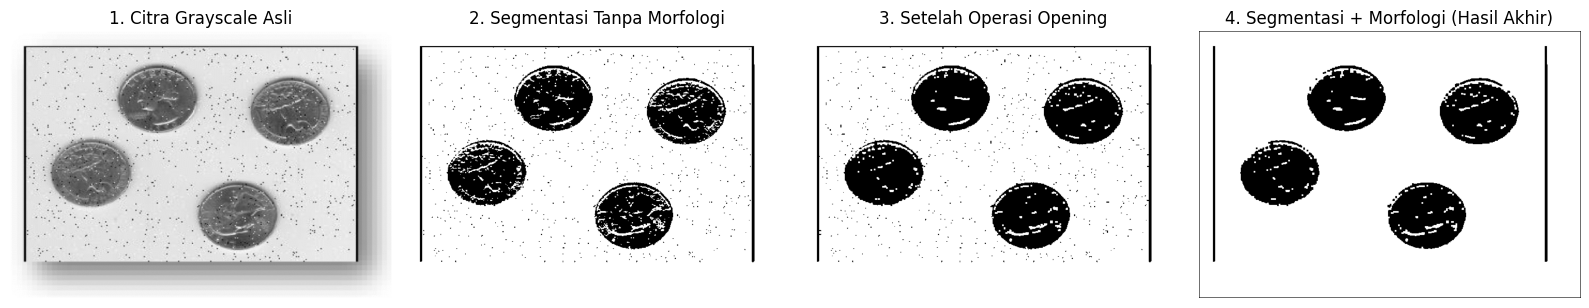

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

def manual_global_thresholding(gray_img, threshold_value=128):
    """Segmentasi biner sederhana berbasis ambang batas (Thresholding) manual."""
    binary_img = np.zeros_like(gray_img, dtype=np.uint8)

    binary_img[gray_img >= threshold_value] = 255
    return binary_img

def manual_erosion(binary_img, kernel):
    """Operasi Erosi Manual (Pengikisan batas objek)."""
    img_bin = (binary_img > 0).astype(np.uint8)
    k_h, k_w = kernel.shape
    pad_h, pad_w = k_h // 2, k_w // 2

    padded_img = np.pad(
        img_bin, ((pad_h, pad_h), (pad_w, pad_w)), mode="constant", constant_values=0
    )
    output = np.zeros_like(binary_img)

    for i in range(binary_img.shape[0]):
        for j in range(binary_img.shape[1]):
            roi = padded_img[i : i + k_h, j : j + k_w]
            if np.all(roi[kernel == 1] == 1):
                output[i, j] = 255
            else:
                output[i, j] = 0
    return output


def manual_dilation(binary_img, kernel):
    """Operasi Dilasi Manual (Penebalan batas objek)."""
    img_bin = (binary_img > 0).astype(np.uint8)
    k_h, k_w = kernel.shape
    pad_h, pad_w = k_h // 2, k_w // 2

    padded_img = np.pad(
        img_bin, ((pad_h, pad_h), (pad_w, pad_w)), mode="constant", constant_values=0
    )
    output = np.zeros_like(binary_img)

    for i in range(binary_img.shape[0]):
        for j in range(binary_img.shape[1]):
            roi = padded_img[i : i + k_h, j : j + k_w]
            if np.any(roi[kernel == 1] == 1):
                output[i, j] = 255
            else:
                output[i, j] = 0
    return output


def manual_opening(binary_img, kernel):
    """Operasi Opening Manual = Erosi diikuti Dilasi."""
    eroded = manual_erosion(binary_img, kernel)
    opened = manual_dilation(eroded, kernel)
    return opened


def manual_closing(binary_img, kernel):
    """Operasi Closing Manual = Dilasi diikuti Erosi."""
    dilated = manual_dilation(binary_img, kernel)
    closed = manual_erosion(dilated, kernel)
    return closed

gray_image = cv2.imread("noisy coint.png", cv2.IMREAD_GRAYSCALE)

if gray_image is None:
    gray_image = np.zeros((200, 200), dtype=np.uint8)
    gray_image[50:150, 50:150] = 200
    noise_bg = np.random.choice([0, 220], size=(200, 200), p=[0.98, 0.02])
    noise_fg = np.random.choice([0, 200], size=(200, 200), p=[0.02, 0.98])
    gray_image = np.where(gray_image == 0, noise_bg, noise_fg).astype(np.uint8)

segmented_raw = manual_global_thresholding(gray_image, threshold_value=128)

kernel_3x3 = np.ones((3, 3), dtype=np.uint8)

segmented_opened = manual_opening(segmented_raw, kernel_3x3)
segmented_morphology = manual_closing(segmented_opened, kernel_3x3)

plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.title("1. Citra Grayscale Asli")
plt.imshow(gray_image, cmap="gray")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.title("2. Segmentasi Tanpa Morfologi")
plt.imshow(segmented_raw, cmap="gray")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.title("3. Setelah Operasi Opening")
plt.imshow(segmented_opened, cmap="gray")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.title("4. Segmentasi + Morfologi (Hasil Akhir)")
plt.imshow(segmented_morphology, cmap="gray")
plt.axis("off")

plt.tight_layout()
plt.show()

# LAPORAN ANALISIS TUGAS PENGOLAHAN CITRA DIGITAL : SEGMENTASI DAN PENGOLAHAN MORFOLOGI CITRA

---

### 1. Pendahuluan & Latar Belakang

Dalam Pengolahan Citra Digital, tahapan **segmentasi citra** bertujuan untuk memisahkan objek utama (*foreground*) dari latar belakang (*background*). Namun, dalam kondisi nyata, segmentasi berbasis ambang batas (*thresholding*) murni sering kali tidak menghasilkan region yang sempurna. Permasalahan yang kerap muncul meliputi:
- Adanya **bintik-bintik derau (noise)** pada latar belakang akibat pencahayaan yang tidak merata.
- Adanya **lubang-lubang kecil (holes) atau retakan** pada bagian dalam objek utama akibat variasi intensitas piksel.

Untuk mengatasi kelemahan tersebut, dilakukan tahap **pasca-pemrosesan (post-processing)** menggunakan **Morphological Image Processing**. Pada tugas `PCD_Assignment03` ini, seluruh fungsi segmentasi dan operasi morfologi diimplementasikan secara manual menggunakan matriks array NumPy tanpa mengandalkan pustaka khusus seperti `cv2.morphologyEx`.

---

### 2. Metodologi Implementasi

#### A. Segmentasi Citra (Simple Global Thresholding)
Segmentasi diimplementasikan dengan mengevaluasi nilai derajat keabuan (*grayscale*) $f(x,y)$ terhadap nilai ambang $T = 128$:
$$
g(x,y) = \begin{cases} 255, & \text{jika } f(x,y) \ge T \\ 0, & \text{jika } f(x,y) < T \end{cases}
$$

#### B. Operasi Morfologi Dasar (Kernel $3 \times 3$)
1. **Erosi (Erosion):** Mengikis batas luar objek. Nilai piksel keluaran menjadi $255$ **hanya jika seluruh elemen kernel $1$ bertumpukan sempurna (FIT)** dengan piksel *foreground* pada *Region of Interest* (ROI).
2. **Dilasi (Dilation):** Memperbesar/mempeltebal batas luar objek. Nilai piksel keluaran menjadi $255$ **jika minimal ada satu elemen kernel $1$ yang bertumpukan (HIT)** dengan piksel *foreground* pada ROI.

#### C. Operasi Morfologi Kombinasi
1. **Opening ($A \circ B = (A \ominus B) \oplus B$):** Operasi Erosi yang dilanjutkan dengan Dilasi. Berfungsi untuk menghapus bintik-bintik derau kecil di latar belakang tanpa merusak ukuran asli objek utama.
2. **Closing ($A \bullet B = (A \oplus B) \ominus B$):** Operasi Dilasi yang dilanjutkan dengan Erosi. Berfungsi untuk menutup celah sempit, retakan, serta mengisi lubang-lubang kecil (*holes*) di dalam objek utama.

---

### 3. Hasil & Pembahasan Analisis Perbandingan

| Tahapan Pemrosesan | Kondisi Visual Citra | Analisis & Efek Morfologi |
| :--- | :--- | :--- |
| **1. Citra Grayscale Asli** | Objek memiliki pencahayaan tidak merata dan derau halus. | Masukan mentah sebelum proses binerisasi. |
| **2. Segmentasi Tanpa Morfologi** | Objek terpisah menjadi biner, tetapi latar belakang ber-noise dan objek berlubang. | Segmentasi murni gagal memisahkan objek secara bersih karena hanya bergantung pada batas piksel tunggal. |
| **3. Setelah Operasi Opening** | Bintik-bintik derau di latar belakang hilang sepenuhnya. | Operasi Erosi menghapus derau kecil, lalu Dilasi mengembalikan ukuran asli objek utama. |
| **4. Segmentasi + Morfologi (Hasil Akhir)** | Latar belakang bersih, lubang di dalam objek terisi penuh, objek menjadi padat (*solid*). | Penggabungan **Opening** dan **Closing** menghasilkan region objek yang utuh, padat, dan siap dianalisis. |

---

### 4. Kesimpulan

1. Implementasi algoritma segmentasi dan morfologi secara manual *from scratch* berhasil dilakukan dengan memanfaatkan operasi iterasi spasial matriks pada NumPy.
2. Segmentasi biner murni tanpa pasca-pemrosesan kurang optimal dalam menangani citra ber-noise atau bertekstur tidak merata.
3. Pemrosesan morfologi kombinasi (**Opening** dan **Closing**) terbukti vital sebagai tahap *post-processing* untuk membersihkan derau latar belakang sekaligus memulihkan keutuhan struktur objek utama.